## EDA

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [106]:
df = pd.read_csv("Trend_Analysis_Dataset.csv")

In [107]:
df.head()

,Record_ID,Month_Number,Month_Date,Phase,Customer_ID,Industry,Region,Plan_Type,Acquisition_Channel,Seats,Customer_Status,MRR_Amount,Total_Company_MRR,Active_Customer_Count
0,1,1,2019-01-01,Phase 1 - Startup,CUST-00001,Management Consulting,Apac,Starter,Outbound Sales,4.0,New,86.64,5200.0,8
1,2,1,2019-01-01,Phase 1 - Startup,CUST-00002,Real Estate Services,India,Starter,Paid Ads,5.0,New,92.10,5200.0,8
2,3,1,2019-01-01,Phase 1 - Startup,CUST-00003,Marketing & Advertising Agency,Apac,Starter,Referral,5.0,New,226.66,5200.0,8
3,4,1,2019-01-01,Phase 1 - Startup,CUST-00004,Media Production,India,Growth,Outbound Sales,20.0,New,335.82,5200.0,8
4,5,1,2019-01-01,Phase 1 - Startup,CUST-00006,Architecture & Design Studio,Middle East,Starter,Content Marketing,5.0,New,178.86,5200.0,8


In [110]:
monthly_df = df.groupby(
    "Month_Number",
    as_index=False
).agg({
    "Month_Date": "first",
    "Phase": "first",
    "Total_Company_MRR": "first"
})

monthly_df = monthly_df.sort_values("Month_Number")
monthly_df.head()

,Month_Number,Month_Date,Phase,Total_Company_MRR
0,1,2019-01-01,Phase 1 - Startup,5200.00
1,2,2019-02-01,Phase 1 - Startup,5809.14
2,3,2019-03-01,Phase 1 - Startup,6412.77
3,4,2019-04-01,Phase 1 - Startup,7158.30
4,5,2019-05-01,Phase 1 - Startup,8090.41


In [111]:
monthly_df.describe()

,Month_Number,Total_Company_MRR
count,84.000000,84.000000
mean,42.500000,86157.846310
std,24.392622,60382.212287
min,1.000000,5200.000000
25%,21.750000,30023.847500
50%,42.500000,76257.385000
75%,63.250000,144742.697500
max,84.000000,187678.310000


In [113]:
print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS - TOTAL COMPANY MRR")
print("=" * 60)

mrr = monthly_df["Total_Company_MRR"]

print("Mean:", round(mrr.mean(), 2))
print("Median:", round(mrr.median(), 2))
print("Minimum:", round(mrr.min(), 2))
print("Maximum:", round(mrr.max(), 2))
print("Variance:", round(mrr.var(), 2))
print("Standard Deviation:", round(mrr.std(), 2))
print("Skewness:", round(mrr.skew(), 2))
print("Kurtosis:", round(mrr.kurtosis(), 2))



DESCRIPTIVE STATISTICS - TOTAL COMPANY MRR
Mean: 86157.85
Median: 76257.38
Minimum: 5200.0
Maximum: 187678.31
Variance: 3646011560.68
Standard Deviation: 60382.21
Skewness: 0.24
Kurtosis: -1.41


##  Categorical EDA

In [114]:

print("\n" + "=" * 60)
print("CATEGORICAL EDA")
print("=" * 60)

print("\nPhase:")
print(df["Phase"].value_counts())

print("\nRegion:")
print(df["Region"].value_counts())

print("\nPlan Type:")
print(df["Plan_Type"].value_counts())

print("\nCustomer Status:")
print(df["Customer_Status"].value_counts())



CATEGORICAL EDA

Phase:
Phase
Phase 3 - Maturation         2733
Phase 2 - Rapid Expansion    1920
Phase 1 - Startup             347
Name: count, dtype: int64

Region:
Region
India            1772
North America    1515
Europe            729
Apac              656
Middle East       322
South               2
North               2
West                1
East                1
Name: count, dtype: int64

Plan Type:
Plan_Type
Starter       2155
Growth        2031
Enterprise     811
Basic            2
Pro              1
Name: count, dtype: int64

Customer Status:
Customer_Status
Existing       3841
Contraction     341
New             317
Expansion       310
Churned         189
Active            2
Name: count, dtype: int64


## Step  — Basic Visualizations

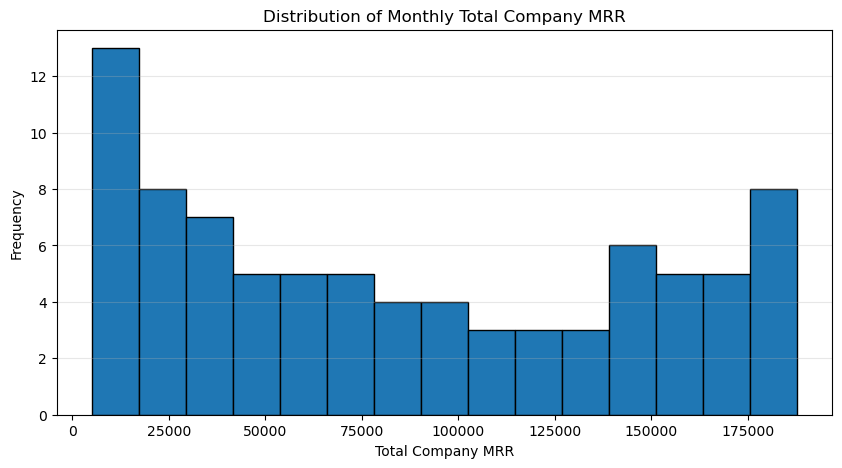

In [115]:
#  REVENUE DISTRIBUTION - HISTOGRAM
plt.figure(figsize=(10, 5))

plt.hist(
    monthly_df["Total_Company_MRR"],
    bins=15,
    edgecolor="black"
)

plt.xlabel("Total Company MRR")
plt.ylabel("Frequency")
plt.title("Distribution of Monthly Total Company MRR")
plt.grid(axis="y", alpha=0.3)
plt.show()


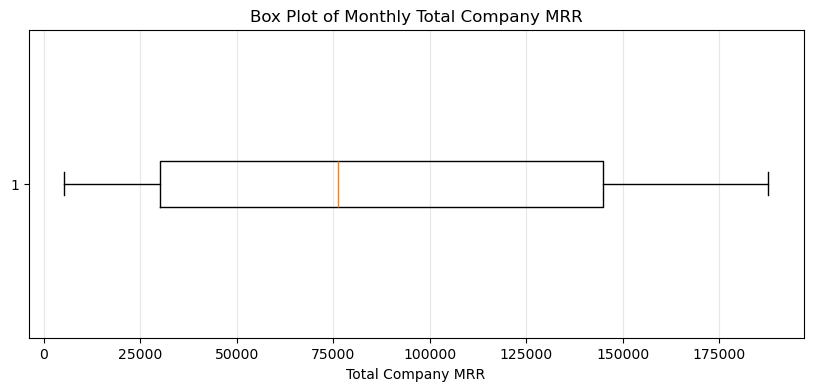

In [116]:
## Revenue Box plot
plt.figure(figsize=(10, 4))

plt.boxplot(
    monthly_df["Total_Company_MRR"],
    vert=False
)

plt.xlabel("Total Company MRR")
plt.title("Box Plot of Monthly Total Company MRR")
plt.grid(axis="x", alpha=0.3)
plt.show()



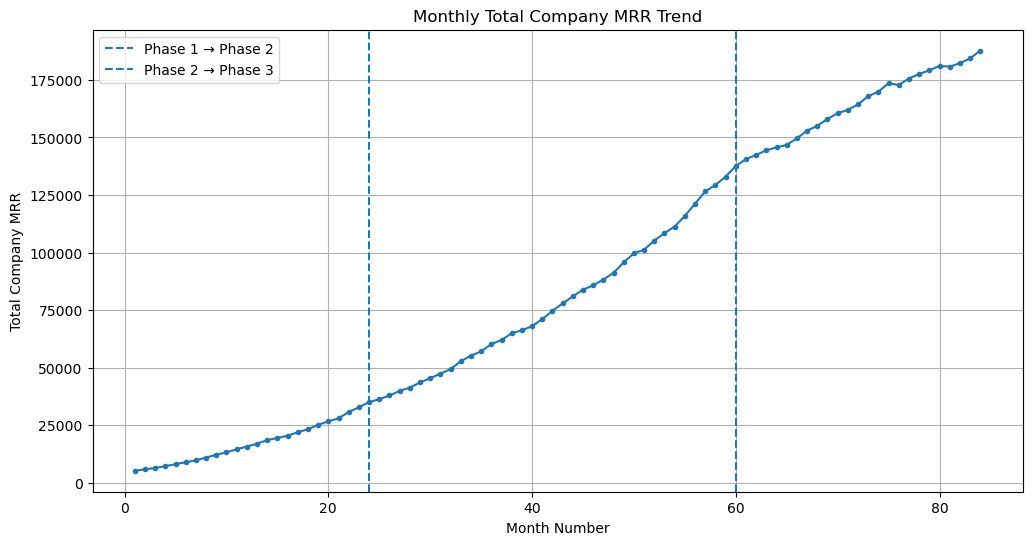

In [117]:
##Revenue Trend
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Total_Company_MRR"],
    marker="o",
    markersize=3
)

plt.axvline(
    x=24,
    linestyle="--",
    label="Phase 1 → Phase 2"
)

plt.axvline(
    x=60,
    linestyle="--",
    label="Phase 2 → Phase 3"
)

plt.xlabel("Month Number")
plt.ylabel("Total Company MRR")
plt.title("Monthly Total Company MRR Trend")
plt.legend()
plt.grid(True)
plt.show()


## Monthly Growth Rate Analysis

In [118]:
monthly_df["Previous_MRR"] = (
    monthly_df["Total_Company_MRR"].shift(1)
)

monthly_df["Monthly_Growth_Rate"] = (
    (monthly_df["Total_Company_MRR"] -
     monthly_df["Previous_MRR"])
    / monthly_df["Previous_MRR"]
) * 100

print("\n" + "=" * 60)
print("MONTHLY GROWTH RATE")
print("=" * 60)

print(
    monthly_df[
        ["Month_Number",
         "Total_Company_MRR",
         "Monthly_Growth_Rate"]
    ].head(10)
)



MONTHLY GROWTH RATE
   Month_Number  Total_Company_MRR  Monthly_Growth_Rate
0             1            5200.00                  NaN
1             2            5809.14            11.714231
2             3            6412.77            10.391039
3             4            7158.30            11.625709
4             5            8090.41            13.021388
5             6            8873.45             9.678620
6             7            9716.31             9.498673
7             8           10938.87            12.582554
8             9           12135.73            10.941350
9            10           13171.51             8.534962


In [119]:
monthly_df[
    ["Month_Number", "Total_Company_MRR",
     "Previous_MRR", "Monthly_Growth_Rate"]
].head(10)

,Month_Number,Total_Company_MRR,Previous_MRR,Monthly_Growth_Rate
0,1,5200.00,NaN,NaN
1,2,5809.14,5200.00,11.714231
2,3,6412.77,5809.14,10.391039
3,4,7158.30,6412.77,11.625709
4,5,8090.41,7158.30,13.021388
5,6,8873.45,8090.41,9.678620
6,7,9716.31,8873.45,9.498673
7,8,10938.87,9716.31,12.582554
8,9,12135.73,10938.87,10.941350
9,10,13171.51,12135.73,8.534962


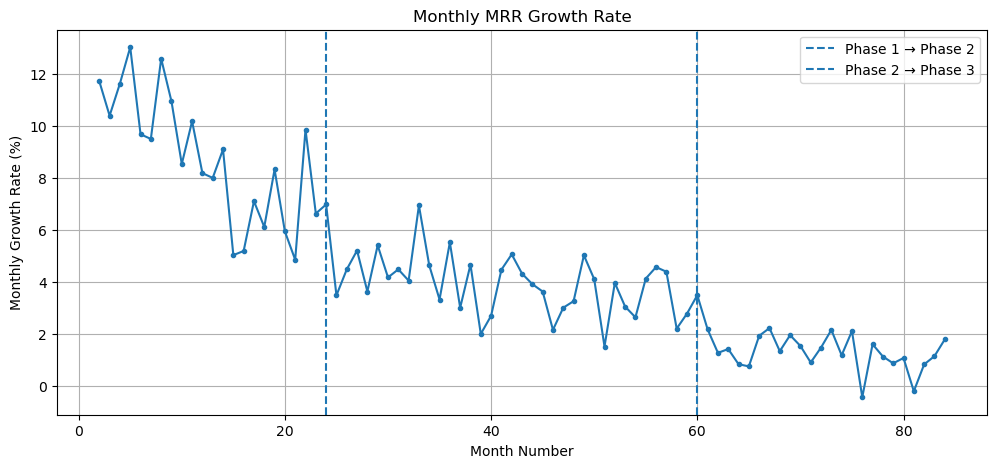

In [120]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Monthly_Growth_Rate"],
    marker="o",
    markersize=3
)

plt.axvline(
    x=24,
    linestyle="--",
    label="Phase 1 → Phase 2"
)

plt.axvline(
    x=60,
    linestyle="--",
    label="Phase 2 → Phase 3"
)

plt.xlabel("Month Number")
plt.ylabel("Monthly Growth Rate (%)")
plt.title("Monthly MRR Growth Rate")
plt.legend()
plt.grid(True)
plt.show()

# Phase-wise Analysis

In [122]:
print("\n" + "=" * 60)
print("PHASE-WISE ANALYSIS")
print("=" * 60)

phase_analysis = monthly_df.groupby("Phase").agg(
    Average_MRR=("Total_Company_MRR", "mean"),
    Minimum_MRR=("Total_Company_MRR", "min"),
    Maximum_MRR=("Total_Company_MRR", "max"),
    Average_Monthly_Growth=("Monthly_Growth_Rate", "mean")
)

print(phase_analysis.round(2))



PHASE-WISE ANALYSIS
                           Average_MRR  Minimum_MRR  Maximum_MRR  \
Phase                                                              
Phase 1 - Startup             17352.05      5200.00     35036.69   
Phase 2 - Rapid Expansion     79605.73     36259.64    137592.71   
Phase 3 - Maturation         164791.82    140599.62    187678.31   

                           Average_Monthly_Growth  
Phase                                              
Phase 1 - Startup                            8.67  
Phase 2 - Rapid Expansion                    3.88  
Phase 3 - Maturation                         1.30  


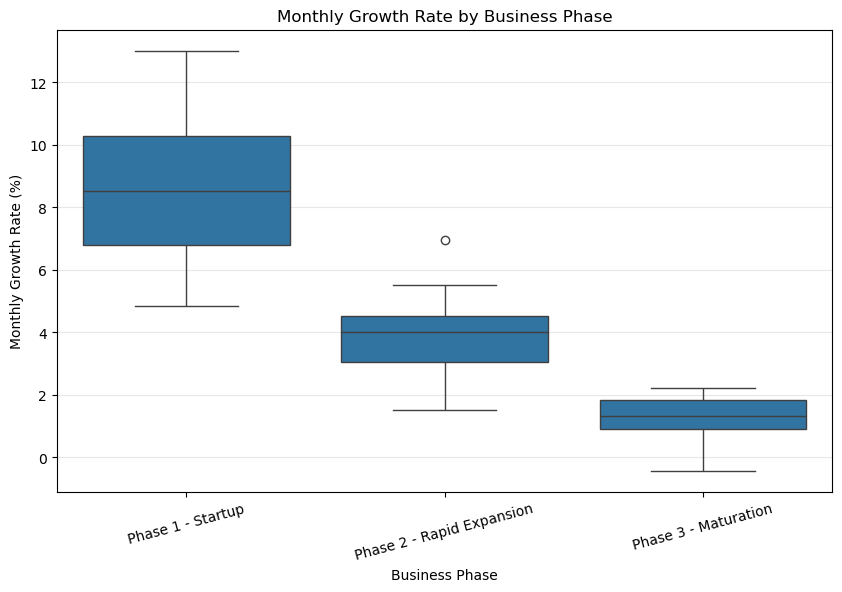

In [123]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=monthly_df,
    x="Phase",
    y="Monthly_Growth_Rate"
)

plt.xlabel("Business Phase")
plt.ylabel("Monthly Growth Rate (%)")
plt.title("Monthly Growth Rate by Business Phase")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [124]:
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("FINAL MONTHLY DATASET CHECK")
print("=" * 60)

print("Number of monthly observations:",
      len(monthly_df))

print("Month range:",
      monthly_df["Month_Number"].min(),
      "to",
      monthly_df["Month_Number"].max())

print("\nMissing values:")
print(monthly_df.isnull().sum())

print("\nMonthly dataset columns:")
print(monthly_df.columns.tolist())


FINAL MONTHLY DATASET CHECK
Number of monthly observations: 84
Month range: 1 to 84

Missing values:
Month_Number           0
Month_Date             0
Phase                  0
Total_Company_MRR      0
Previous_MRR           1
Monthly_Growth_Rate    1
dtype: int64

Monthly dataset columns:
['Month_Number', 'Month_Date', 'Phase', 'Total_Company_MRR', 'Previous_MRR', 'Monthly_Growth_Rate']


## CAGR by Phase

In [100]:
## CAGR by Phase

cagr_results = []

for phase in monthly_df["Phase"].dropna().unique():

    # Select one phase
    phase_data = monthly_df[
        monthly_df["Phase"] == phase
    ].sort_values("Month_Number")

    # Beginning and ending MRR
    beginning_mrr = phase_data["Total_Company_MRR"].iloc[0]
    ending_mrr = phase_data["Total_Company_MRR"].iloc[-1]

    # Elapsed months between beginning and ending month
    number_of_months = (
        phase_data["Month_Number"].iloc[-1]
        - phase_data["Month_Number"].iloc[0]
    )

    # Convert months into years
    number_of_years = number_of_months / 12

    # CAGR calculation
    cagr = (
        (ending_mrr / beginning_mrr)
        ** (1 / number_of_years)
        - 1
    ) * 100

    # Store results
    cagr_results.append({
        "Phase": phase,
        "Beginning_MRR": beginning_mrr,
        "Ending_MRR": ending_mrr,
        "Number_of_Months": number_of_months,
        "Number_of_Years": number_of_years,
        "CAGR_Percent": cagr
    })

# Create CAGR DataFrame
cagr_df = pd.DataFrame(cagr_results)

# Round values for display
cagr_df["Beginning_MRR"] = cagr_df["Beginning_MRR"].round(2)
cagr_df["Ending_MRR"] = cagr_df["Ending_MRR"].round(2)
cagr_df["CAGR_Percent"] = cagr_df["CAGR_Percent"].round(2)

print(cagr_df)

                       Phase  Beginning_MRR  Ending_MRR  Number_of_Months  \
0          Phase 1 - Startup        5200.00    35036.69                23   
1  Phase 2 - Rapid Expansion       36259.64   137592.71                35   
2       Phase 3 - Maturation      140599.62   187678.31                23   

   Number_of_Years  CAGR_Percent  
0         1.916667        170.56  
1         2.916667         57.97  
2         1.916667         16.26  


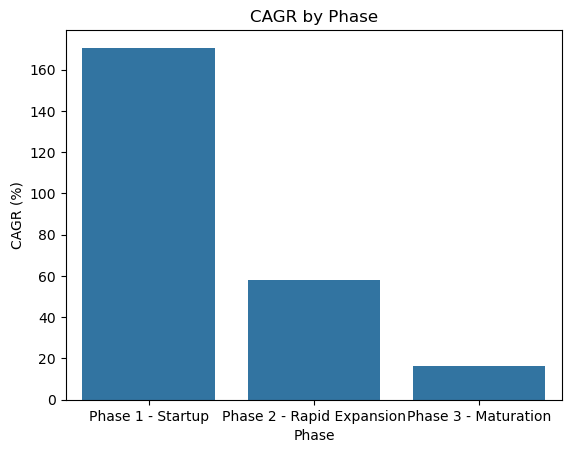

In [59]:
sns.barplot(
    data=cagr_df,
    x="Phase",
    y="CAGR_Percent"
)

plt.title("CAGR by Phase")
plt.xlabel("Phase")
plt.ylabel("CAGR (%)")
plt.show()

## Correlation Analysis

In [60]:
monthly_correlation = df.groupby(
    "Month_Number",
    as_index=False
).agg({
    "Total_Company_MRR": "first",
    "Active_Customer_Count": "first",
    "Seats": "sum",
    "MRR_Amount": "sum"
})

In [61]:
correlation = monthly_correlation[
    [
        "Total_Company_MRR",
        "Active_Customer_Count",
        "Seats",
        "MRR_Amount"
    ]
].corr()

print(correlation)

                       Total_Company_MRR  Active_Customer_Count     Seats  \
Total_Company_MRR               1.000000               0.994085  0.962727   
Active_Customer_Count           0.994085               1.000000  0.982679   
Seats                           0.962727               0.982679  1.000000   
MRR_Amount                      0.997804               0.992152  0.964666   

                       MRR_Amount  
Total_Company_MRR        0.997804  
Active_Customer_Count    0.992152  
Seats                    0.964666  
MRR_Amount               1.000000  


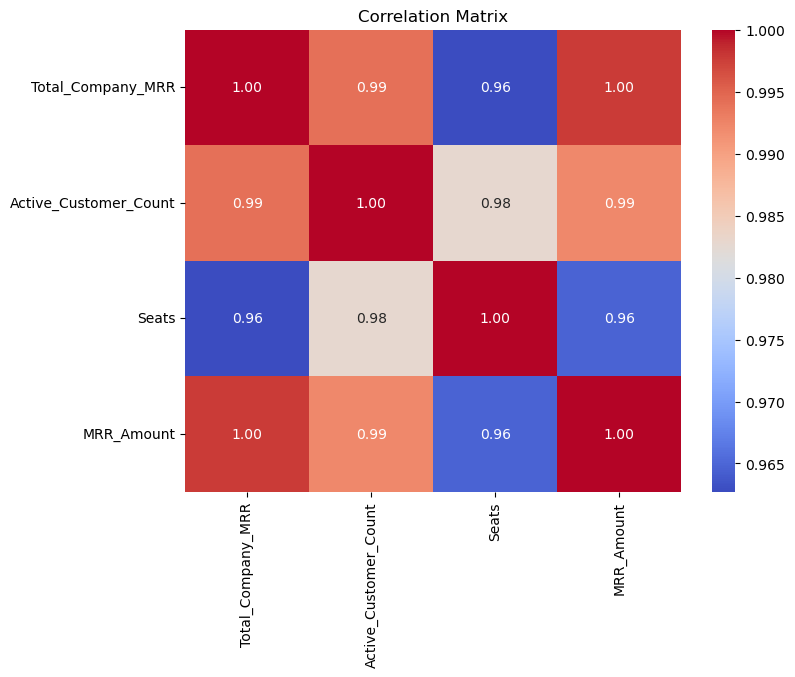

In [62]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

## Time series Dignoistics

In [63]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

<Figure size 1000x500 with 0 Axes>

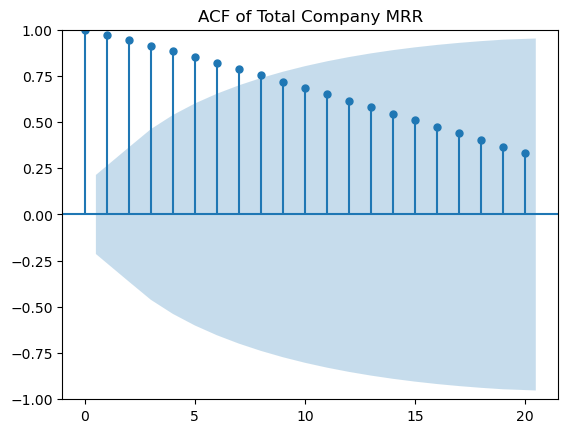

In [64]:
## ACF

plt.figure(figsize=(10, 5))

plot_acf(
    monthly_df["Total_Company_MRR"],
    lags=20
)

plt.title("ACF of Total Company MRR")
plt.show()

<Figure size 1000x500 with 0 Axes>

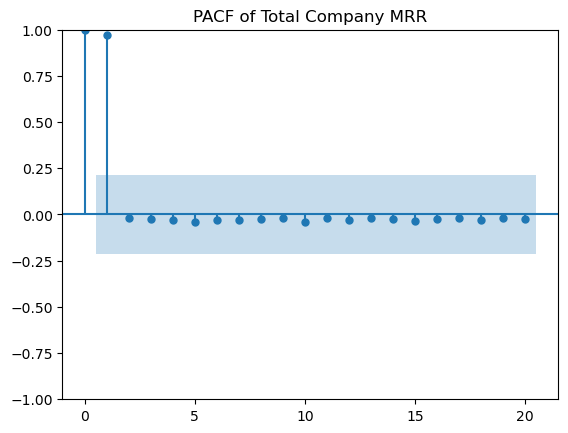

In [65]:
##PACF
plt.figure(figsize=(10, 5))

plot_pacf(
    monthly_df["Total_Company_MRR"],
    lags=20,
    method="ywm"
)

plt.title("PACF of Total Company MRR")
plt.show()

In [66]:
##ADF test
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(
    monthly_df["Total_Company_MRR"]
)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

ADF Statistic: 0.9711426416147948
p-value: 0.9939519428707115


In [67]:
##KPSS
from statsmodels.tsa.stattools import kpss

kpss_result = kpss(
    monthly_df["Total_Company_MRR"],
    regression="ct",
    nlags="auto"
)

print("KPSS Statistic:", kpss_result[0])
print("p-value:", kpss_result[1])

KPSS Statistic: 0.30552806467722826
p-value: 0.01


C:\Users\ELCOT\AppData\Local\Temp\ipykernel_10408\92664358.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(


## Time-Series Decomposition

In [68]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

In [69]:
decomposition = seasonal_decompose(
    monthly_df["Total_Company_MRR"],
    model="additive",
    period=12
)

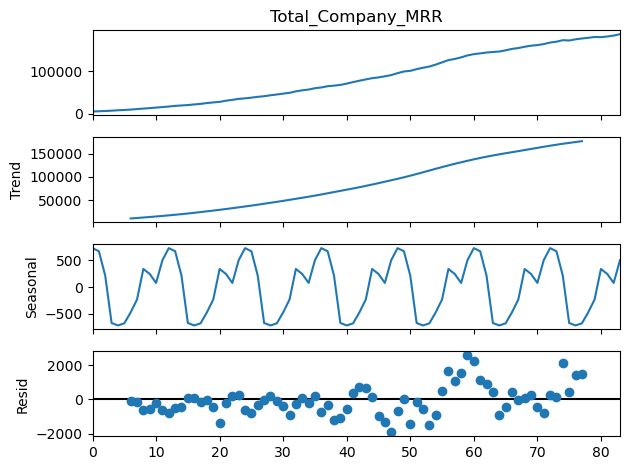

In [70]:
decomposition.plot((12, 8))

plt.show()

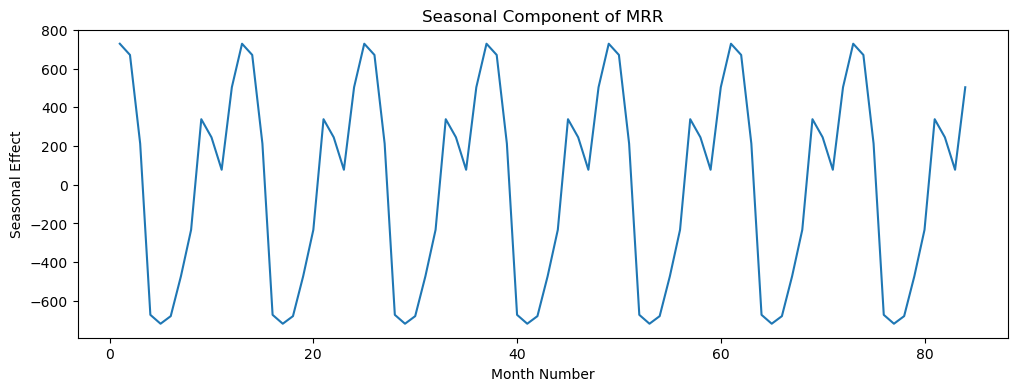

In [71]:
##Seasonal Component
plt.figure(figsize=(12, 4))

plt.plot(
    monthly_df["Month_Number"],
    decomposition.seasonal
)

plt.title("Seasonal Component of MRR")
plt.xlabel("Month Number")
plt.ylabel("Seasonal Effect")

plt.show()

## observation
* The trend component shows a continuous upward movement in Total Company MRR, indicating an overall increasing revenue trend over the study period.
* The seasonal component shows a similar recurring pattern across the periods, indicating the presence of a consistent seasonal pattern
in monthly MRR.
* The residual component shows predominantly positive values between Months 55 and 65, indicating that the actual MRR was higher than the level 
explained by the trend and seasonal components during this period.
* The positive residual pattern around Months 55–65 may indicate an unusual deviation from the underlying trend and requires 
further statistical investigation.


## Model Fitting

In [72]:
## Linear Regression
import statsmodels.api as sm

X = monthly_df["Month_Number"]
y = monthly_df["Total_Company_MRR"]

X = sm.add_constant(X)

linear_model = sm.OLS(y, X).fit()

print(linear_model.summary())

                            OLS Regression Results                            
Dep. Variable:      Total_Company_MRR   R-squared:                       0.981
Model:                            OLS   Adj. R-squared:                  0.981
Method:                 Least Squares   F-statistic:                     4319.
Date:                Mon, 28 Sep 2026   Prob (F-statistic):           1.06e-72
Time:                        18:41:27   Log-Likelihood:                -876.11
No. Observations:                  84   AIC:                             1756.
Df Residuals:                      82   BIC:                             1761.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const        -1.806e+04   1825.724     -9.894   

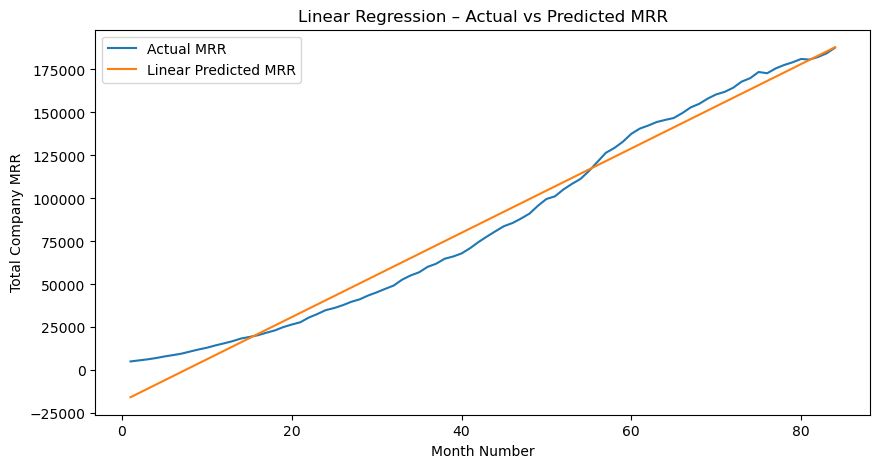

In [73]:
##predicted MRR
monthly_df["Linear_Predicted_MRR"] = linear_model.predict(X)

## Actual Vs Predicted MRR
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Total_Company_MRR"],
    label="Actual MRR"
)

plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Linear_Predicted_MRR"],
    label="Linear Predicted MRR"
)

plt.title("Linear Regression – Actual vs Predicted MRR")
plt.xlabel("Month Number")
plt.ylabel("Total Company MRR")
plt.legend()

plt.show()

## Observation
* R² is **0.981**, indicating a strong model fit.
* Adjusted R² is also **0.981**.
* MRR increases by approximately **2,452 units per month** according to the model.
* The Month Number coefficient is statistically significant (**p < 0.001**).
* The **Durbin-Watson value is 0.021**, indicating strong positive autocorrelation in the residuals.
* Therefore, the linear model should be compared with other models before selecting the best fit.


In [74]:
## Exponentional model
import numpy as np
import statsmodels.api as sm

# Independent variable
X = monthly_df["Month_Number"]

# Dependent variable
y = monthly_df["Total_Company_MRR"]

# Log transform MRR
log_y = np.log(y)

# Add constant
X_exp = sm.add_constant(X)

# Fit Exponential Model
exponential_model = sm.OLS(log_y, X_exp).fit()

# Model summary
print(exponential_model.summary())

                            OLS Regression Results                            
Dep. Variable:      Total_Company_MRR   R-squared:                       0.927
Model:                            OLS   Adj. R-squared:                  0.926
Method:                 Least Squares   F-statistic:                     1042.
Date:                Mon, 28 Sep 2026   Prob (F-statistic):           2.18e-48
Time:                        18:41:27   Log-Likelihood:                -9.9628
No. Observations:                  84   AIC:                             23.93
Df Residuals:                      82   BIC:                             28.79
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            9.2799      0.061    152.848   

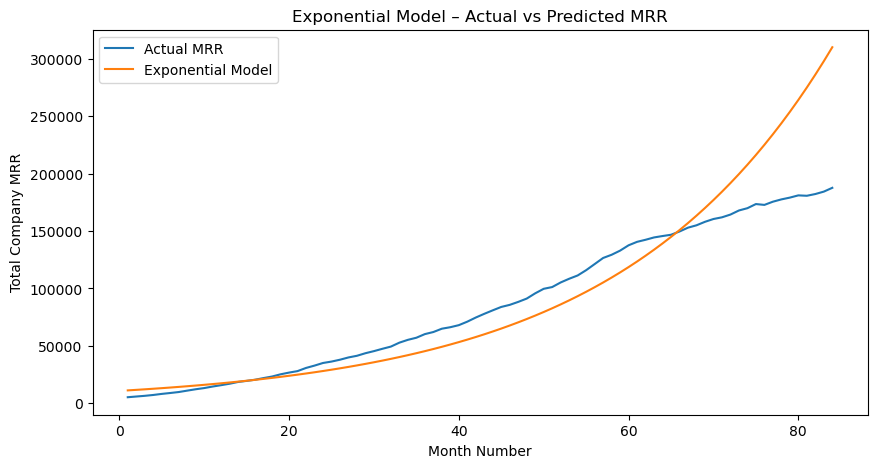

In [75]:
## Predicted MRR
log_predicted = exponential_model.predict(X_exp)

monthly_df["Exponential_Predicted_MRR"] = np.exp(log_predicted)

## Actual vs Predicted
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Total_Company_MRR"],
    label="Actual MRR"
)

plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Exponential_Predicted_MRR"],
    label="Exponential Model"
)

plt.title("Exponential Model – Actual vs Predicted MRR")
plt.xlabel("Month Number")
plt.ylabel("Total Company MRR")
plt.legend()

plt.show()

## Exponential Model Observation

* R² is **0.927**, indicating a strong fit on the log-transformed MRR scale.
* The Month Number coefficient is statistically significant (**p < 0.001**).
* The model indicates an exponential growth pattern in MRR.
* Durbin-Watson is **0.012**, indicating strong positive autocorrelation in the residuals.




In [76]:
## Logarithmic model
import numpy as np
import statsmodels.api as sm

# Independent variable
X = np.log(monthly_df["Month_Number"] + 1)

# Dependent variable
y = monthly_df["Total_Company_MRR"]

# Add constant
X_log = sm.add_constant(X)

# Fit Logarithmic Model
logarithmic_model = sm.OLS(y, X_log).fit()

# Model summary
print(logarithmic_model.summary())

                            OLS Regression Results                            
Dep. Variable:      Total_Company_MRR   R-squared:                       0.748
Model:                            OLS   Adj. R-squared:                  0.745
Method:                 Least Squares   F-statistic:                     244.0
Date:                Mon, 28 Sep 2026   Prob (F-statistic):           2.67e-26
Time:                        18:41:28   Log-Likelihood:                -985.42
No. Observations:                  84   AIC:                             1975.
Df Residuals:                      82   BIC:                             1980.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const        -1.322e+05   1.44e+04     -9.202   

In [77]:
## Predicted MRR 
monthly_df["Logarithmic_Predicted_MRR"] = (
    logarithmic_model.predict(X_log)
)

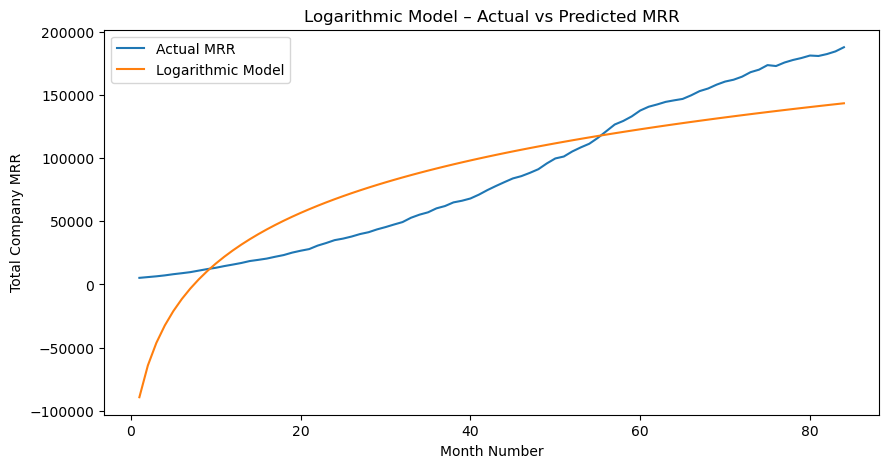

In [78]:
## Actual vs Logarithmic
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Total_Company_MRR"],
    label="Actual MRR"
)

plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Logarithmic_Predicted_MRR"],
    label="Logarithmic Model"
)

plt.title("Logarithmic Model – Actual vs Predicted MRR")
plt.xlabel("Month Number")
plt.ylabel("Total Company MRR")
plt.legend()

plt.show()


## Logarithmic Model Observation**

* R² is **0.748**, showing a moderate fit.
* The Month Number coefficient is statistically significant (**p < 0.001**).
* The model explains less variation than the linear and exponential models.
* Durbin-Watson is **0.022**, indicating strong positive autocorrelation in the residuals.


Logistic Model Parameters
-------------------------
L: 210168.44426705563
k: 0.06287842116513084
x0: 51.2180314248061

Actual vs Logistic Predicted MRR
   Month_Number  Total_Company_MRR  Logistic_Predicted_MRR
0             1            5200.00             8573.120705
1             2            5809.14             9105.389190
2             3            6412.77             9669.118954
3             4            7158.30            10265.968150
4             5            8090.41            10897.656819
5             6            8873.45            11565.965846
6             7            9716.31            12272.735379
7             8           10938.87            13019.862606
8             9           12135.73            13809.298868
9            10           13171.51            14643.045985


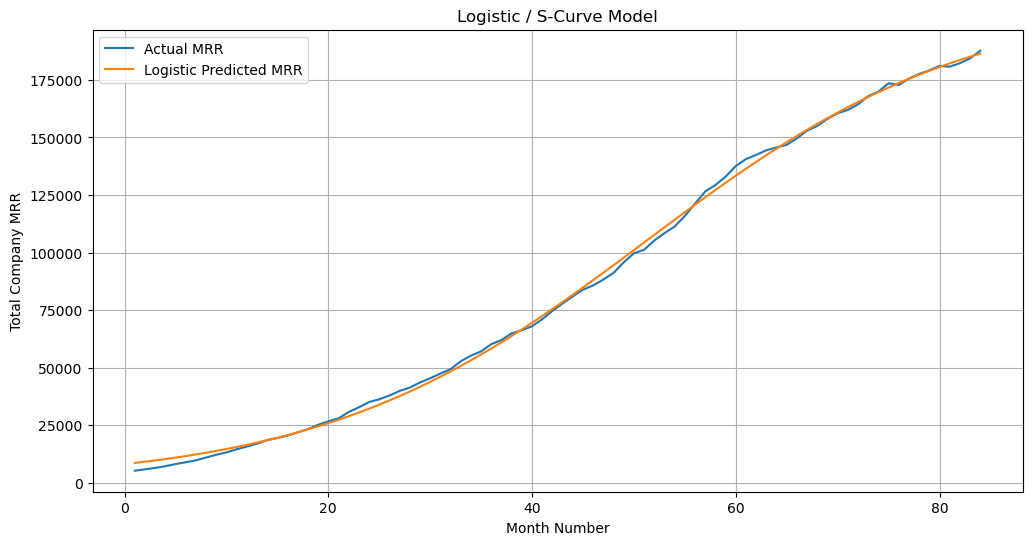

In [79]:
# Logistic / S-Curve Model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Step 1: Define Logistic Model
def logistic_model(x, L, k, x0):
    return L / (1 + np.exp(-k * (x - x0)))

# Step 2: Prepare X and Y
X = monthly_df["Month_Number"].values
y = monthly_df["Total_Company_MRR"].values

# Step 3: Initial values
initial_guess = [
    y.max() * 2,
    0.05,
    X.mean()
]

# Step 4: Fit Logistic Model
logistic_params, covariance = curve_fit(
    logistic_model,
    X,
    y,
    p0=initial_guess,
    maxfev=10000
)

# Step 5: Get model parameters
L, k, x0 = logistic_params

print("Logistic Model Parameters")
print("-------------------------")
print("L:", L)
print("k:", k)
print("x0:", x0)

# Step 6: Calculate predicted MRR
logistic_pred = logistic_model(
    X,
    L,
    k,
    x0
)

# Step 7: Add predictions to dataframe
monthly_df["Logistic_Predicted_MRR"] = logistic_pred

# Step 8: Display actual vs predicted
print("\nActual vs Logistic Predicted MRR")
print(
    monthly_df[
        [
            "Month_Number",
            "Total_Company_MRR",
            "Logistic_Predicted_MRR"
        ]
    ].head(10)
)

# Step 9: Plot Actual vs Logistic Prediction
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Total_Company_MRR"],
    label="Actual MRR"
)

plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Logistic_Predicted_MRR"],
    label="Logistic Predicted MRR"
)

plt.xlabel("Month Number")
plt.ylabel("Total Company MRR")
plt.title("Logistic / S-Curve Model")
plt.legend()
plt.grid(True)

plt.show()

## Model Evaluation

In [80]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Actual MRR
actual = monthly_df["Total_Company_MRR"]

# Predictions from all 4 models
predictions = {
    "Linear": monthly_df["Linear_Predicted_MRR"],
    "Exponential": monthly_df["Exponential_Predicted_MRR"],
    "Logarithmic": monthly_df["Logarithmic_Predicted_MRR"],
    "Logistic": monthly_df["Logistic_Predicted_MRR"]
}

# Store evaluation results
evaluation_results = []

for model_name, predicted in predictions.items():

    r2 = r2_score(actual, predicted)

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    # Number of parameters
    if model_name == "Logistic":
        parameters = 3
    else:
        parameters = 2

    rse = np.sqrt(
        np.sum((actual - predicted) ** 2)
        / (len(actual) - parameters)
    )

    evaluation_results.append({
        "Model": model_name,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
        "RSE": rse
    })

# Create comparison table
evaluation_df = pd.DataFrame(evaluation_results)

print(evaluation_df)

         Model        R2           MAE          RMSE           RSE
0       Linear  0.981369   7137.105647   8192.619718   8291.927825
1  Exponential  0.712180  19807.587395  32200.946620  32591.275376
2  Logarithmic  0.748497  26434.450467  30100.931773  30465.804874
3     Logistic  0.999034   1550.038215   1865.980171   1900.221195


In [81]:
# Calculate residuals for all 4 models

monthly_df["Linear_Residual"] = (
    monthly_df["Total_Company_MRR"]
    - monthly_df["Linear_Predicted_MRR"]
)

monthly_df["Exponential_Residual"] = (
    monthly_df["Total_Company_MRR"]
    - monthly_df["Exponential_Predicted_MRR"]
)

monthly_df["Logarithmic_Residual"] = (
    monthly_df["Total_Company_MRR"]
    - monthly_df["Logarithmic_Predicted_MRR"]
)

monthly_df["Logistic_Residual"] = (
    monthly_df["Total_Company_MRR"]
    - monthly_df["Logistic_Predicted_MRR"]
)

# Display residuals
print(
    monthly_df[
        [
            "Month_Number",
            "Linear_Residual",
            "Exponential_Residual",
            "Logarithmic_Residual",
            "Logistic_Residual"
        ]
    ].head(10)
)

   Month_Number  Linear_Residual  Exponential_Residual  Logarithmic_Residual  \
0             1     20811.004997          -5958.603192          94446.610822   
1             2     18967.883520          -5805.552909          69906.065577   
2             3     17119.252043          -5676.654550          52665.709922   
3             4     15412.520565          -5425.260072          39570.369358   
4             5     13892.369088          -5007.482579          29193.664678   
5             6     12223.147611          -4759.797588          20415.238105   
6             7     10613.746134          -4474.174361          12975.579023   
7             8      9384.044656          -3831.627279           6892.439434   
8             9      8128.643179          -3238.487279           1554.128459   
9            10      6712.161702          -2831.103350          -3321.872789   

   Logistic_Residual  
0       -3373.120705  
1       -3296.249190  
2       -3256.348954  
3       -3107.668150  
4   

In [82]:
## Durbin Watson
from statsmodels.stats.stattools import durbin_watson

# Durbin-Watson values for all 4 models

dw_results = {
    "Linear": durbin_watson(monthly_df["Linear_Residual"]),
    "Exponential": durbin_watson(monthly_df["Exponential_Residual"]),
    "Logarithmic": durbin_watson(monthly_df["Logarithmic_Residual"]),
    "Logistic": durbin_watson(monthly_df["Logistic_Residual"])
}

# Display results
dw_df = pd.DataFrame(
    list(dw_results.items()),
    columns=["Model", "Durbin_Watson"]
)

print(dw_df)

         Model  Durbin_Watson
0       Linear       0.020865
1  Exponential       0.011868
2  Logarithmic       0.022059
3     Logistic       0.215658


## Observation

All four models have DW values far below 2, indicating strong positive autocorrelation in their residuals.

Linear → strong positive autocorrelation

Exponential → strong positive autocorrelation

Logarithmic → strong positive autocorrelation

Logistic → positive autocorrelation is still present, although its DW is higher than the other three

So, high R² alone is not enough to conclude that the residuals are well behaved. We still need to inspect the residual pattern.

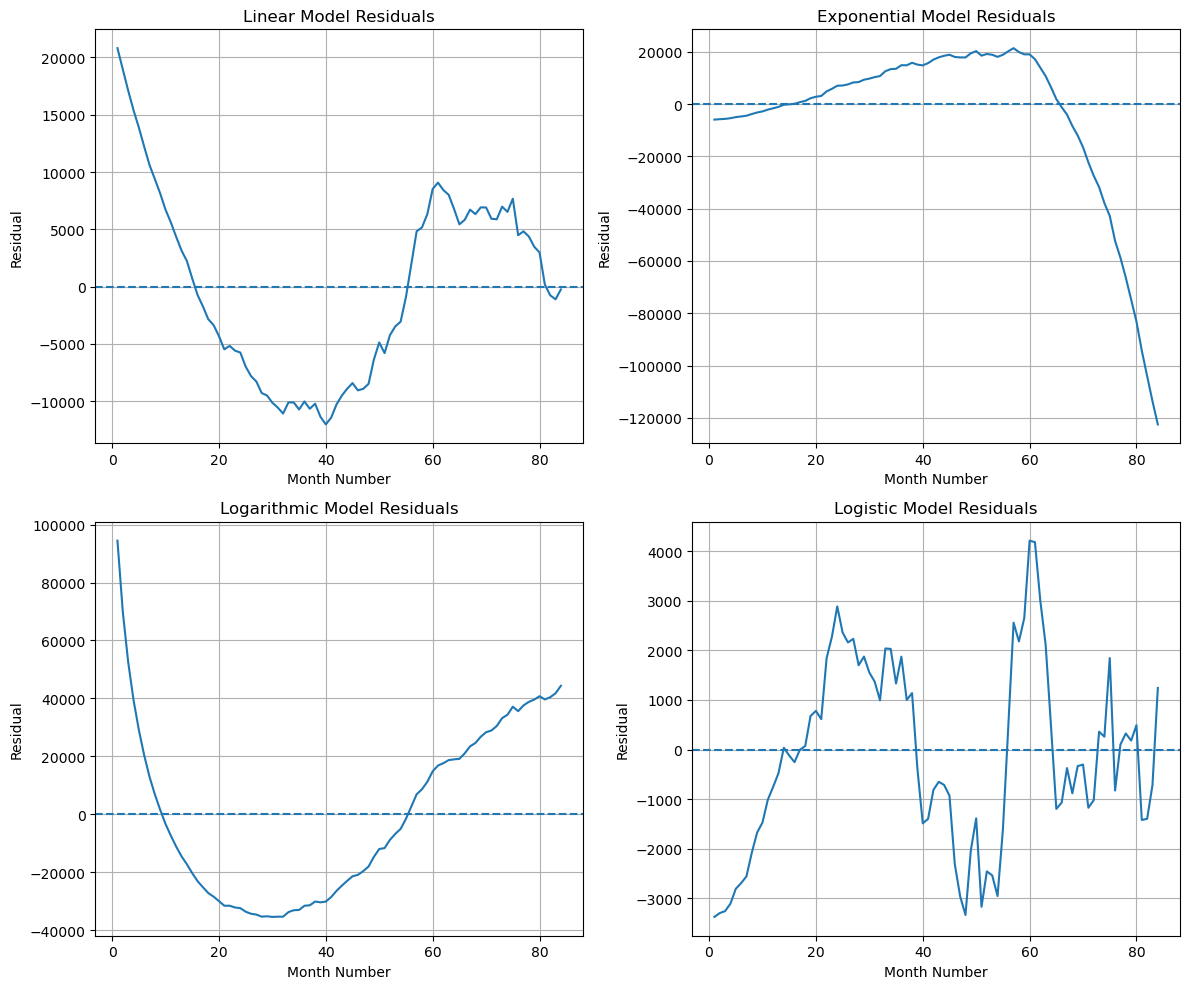

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

# Linear
plt.subplot(2, 2, 1)
plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Linear_Residual"]
)
plt.axhline(y=0, linestyle="--")
plt.title("Linear Model Residuals")
plt.xlabel("Month Number")
plt.ylabel("Residual")
plt.grid(True)

# Exponential
plt.subplot(2, 2, 2)
plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Exponential_Residual"]
)
plt.axhline(y=0, linestyle="--")
plt.title("Exponential Model Residuals")
plt.xlabel("Month Number")
plt.ylabel("Residual")
plt.grid(True)

# Logarithmic
plt.subplot(2, 2, 3)
plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Logarithmic_Residual"]
)
plt.axhline(y=0, linestyle="--")
plt.title("Logarithmic Model Residuals")
plt.xlabel("Month Number")
plt.ylabel("Residual")
plt.grid(True)

# Logistic
plt.subplot(2, 2, 4)
plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Logistic_Residual"]
)
plt.axhline(y=0, linestyle="--")
plt.title("Logistic Model Residuals")
plt.xlabel("Month Number")
plt.ylabel("Residual")
plt.grid(True)

plt.tight_layout()
plt.show()

| **Model**       | **Observation from Residual Plot**                                                                                                                                                                                              |
| --------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Linear**      | Residuals show a clear systematic pattern rather than random distribution. Residuals decrease from positive to negative values and then increase again. A positive residual pattern is visible around Months 55–75.             |
| **Exponential** | Residuals show a strong systematic pattern. They are mostly positive during the middle period, followed by very large negative residuals toward the later months.                                                               |
| **Logarithmic** | Residuals show a pronounced curved/U-shaped pattern. Large positive residuals occur at the beginning and end, while negative residuals dominate the middle period.                                                              |
| **Logistic**    | Residuals are smaller in magnitude compared with the other models and are generally closer to zero. However, systematic patterns remain around Months 20–40 and 55–65, indicating that the residuals are not completely random. |


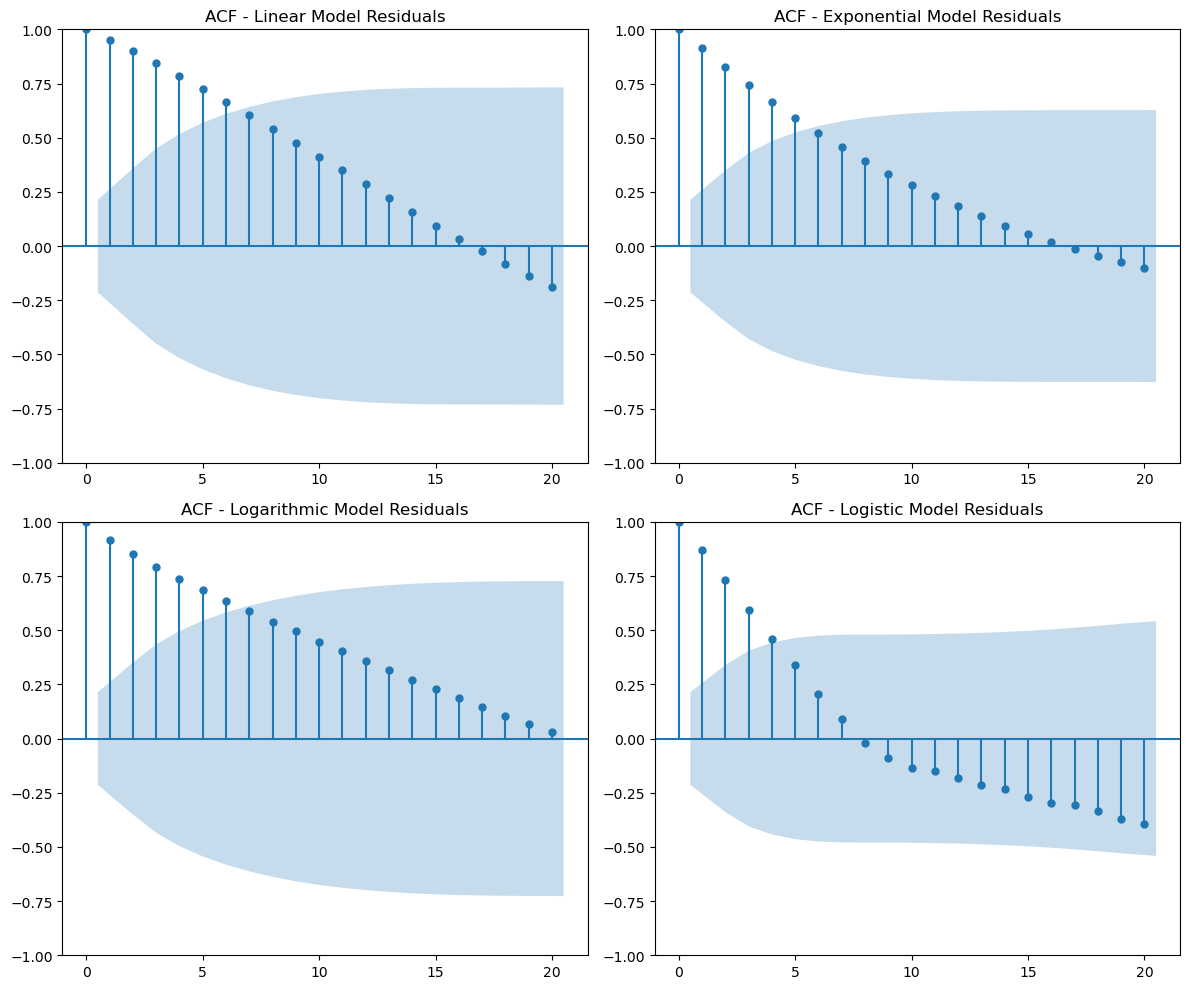

In [84]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

# Linear
plt.subplot(2, 2, 1)
plot_acf(
    monthly_df["Linear_Residual"],
    lags=20,
    ax=plt.gca()
)
plt.title("ACF - Linear Model Residuals")

# Exponential
plt.subplot(2, 2, 2)
plot_acf(
    monthly_df["Exponential_Residual"],
    lags=20,
    ax=plt.gca()
)
plt.title("ACF - Exponential Model Residuals")

# Logarithmic
plt.subplot(2, 2, 3)
plot_acf(
    monthly_df["Logarithmic_Residual"],
    lags=20,
    ax=plt.gca()
)
plt.title("ACF - Logarithmic Model Residuals")

# Logistic
plt.subplot(2, 2, 4)
plot_acf(
    monthly_df["Logistic_Residual"],
    lags=20,
    ax=plt.gca()
)
plt.title("ACF - Logistic Model Residuals")

plt.tight_layout()
plt.show()

| **Model**       | **Observation from ACF Plot**                                                                                                                                                                                                          |
| --------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Linear**      | ACF starts very high and gradually decreases across the lags. Several early lags remain outside the confidence band, indicating strong positive autocorrelation in the residuals.                                                      |
| **Exponential** | ACF shows strong positive autocorrelation at the initial lags and gradually declines toward zero. Several early lags are significant, indicating that residuals are not independent.                                                   |
| **Logarithmic** | ACF remains strongly positive across many lags and declines slowly. Multiple lags are outside the confidence band, indicating persistent positive autocorrelation in the residuals.                                                    |
| **Logistic**    | ACF starts strongly positive and declines more rapidly than the other models. It crosses near zero around the middle lags and becomes negative at later lags. However, significant autocorrelation is still present at the early lags. |


In [85]:
# Combine model evaluation and Durbin-Watson results

model_comparison = evaluation_df.copy()

model_comparison["Durbin_Watson"] = [
    dw_results["Linear"],
    dw_results["Exponential"],
    dw_results["Logarithmic"],
    dw_results["Logistic"]
]

print(model_comparison)

         Model        R2           MAE          RMSE           RSE  \
0       Linear  0.981369   7137.105647   8192.619718   8291.927825   
1  Exponential  0.712180  19807.587395  32200.946620  32591.275376   
2  Logarithmic  0.748497  26434.450467  30100.931773  30465.804874   
3     Logistic  0.999034   1550.038215   1865.980171   1900.221195   

   Durbin_Watson  
0       0.020865  
1       0.011868  
2       0.022059  
3       0.215658  


## Observation
Logistic model:

Highest R² → 0.999

Lowest MAE → 1,550

Lowest RMSE → 1,866

Lowest RSE → 1,900

Residual magnitude comparatively small

But DW = 0.216, so residual autocorrelation remains.

Therefore, based on model fit and prediction-error metrics, Logistic is the strongest of the four models.

## Chow test 

In [86]:
import statsmodels.api as sm
from scipy.stats import f

def chow_test(data, breakpoint):

    # Before breakpoint
    before = data[data["Month_Number"] < breakpoint]

    # After breakpoint
    after = data[data["Month_Number"] >= breakpoint]

    # Pooled model
    X = sm.add_constant(data["Month_Number"])
    y = data["Total_Company_MRR"]

    pooled_model = sm.OLS(y, X).fit()

    # Before model
    X_before = sm.add_constant(before["Month_Number"])
    y_before = before["Total_Company_MRR"]

    before_model = sm.OLS(y_before, X_before).fit()

    # After model
    X_after = sm.add_constant(after["Month_Number"])
    y_after = after["Total_Company_MRR"]

    after_model = sm.OLS(y_after, X_after).fit()

    # Sum of Squared Residuals
    SSR_pooled = sum(pooled_model.resid ** 2)
    SSR_before = sum(before_model.resid ** 2)
    SSR_after = sum(after_model.resid ** 2)

    # Number of parameters
    k = 2

    # Sample sizes
    n_before = len(before)
    n_after = len(after)

    # Chow F-statistic
    chow_stat = (
        ((SSR_pooled - (SSR_before + SSR_after)) / k)
        /
        ((SSR_before + SSR_after) /
         (n_before + n_after - 2 * k))
    )

    # p-value
    p_value = f.sf(
        chow_stat,
        k,
        n_before + n_after - 2 * k
    )

    return chow_stat, p_value

In [87]:
## Break point 1
chow_24, p_24 = chow_test(
    monthly_df,
    24
)

print("Chow Test at Month 24")
print("F-statistic:", chow_24)
print("p-value:", p_24)
print("_______________________")
## Break point 2 
chow_60, p_60 = chow_test(
    monthly_df,
    60
)

print("Chow Test at Month 60")
print("F-statistic:", chow_60)
print("p-value:", p_60)

Chow Test at Month 24
F-statistic: 152.98015839486055
p-value: 4.590852209343111e-28
_______________________
Chow Test at Month 60
F-statistic: 33.96717516253407
p-value: 2.0933330388198132e-11


## Observation 
• A significant structural break is detected at Month 24 (p < 0.05).                   

• A significant structural break is also detected at Month 60 (p < 0.05).

• This indicates that the MRR trend relationship changed significantly at both phase boundaries.

• Therefore, the predefined three-phase structure is supported by the Chow Test.

## Growth Rate Significance Test

In [88]:
phase1 = monthly_df[
    monthly_df["Phase"] == "Phase 1 - Startup"
]["Monthly_Growth_Rate"].dropna()

phase2 = monthly_df[
    monthly_df["Phase"] == "Phase 2 - Rapid Expansion"
]["Monthly_Growth_Rate"].dropna()

phase3 = monthly_df[
    monthly_df["Phase"] == "Phase 3 - Maturation"
]["Monthly_Growth_Rate"].dropna()

In [89]:
print("Phase 1 count:", len(phase1))
print("Phase 2 count:", len(phase2))
print("Phase 3 count:", len(phase3))

Phase 1 count: 23
Phase 2 count: 36
Phase 3 count: 24


In [90]:
## ANOVA TEST
from scipy.stats import f_oneway

anova_result = f_oneway(phase1, phase2, phase3)

print("F-statistic:", anova_result.statistic)
print("p-value:", anova_result.pvalue)

F-statistic: 142.46607832662846
p-value: 4.316324944312655e-27


## Observation
The ANOVA test produced an F-statistic of 142.47.
    
The p-value is 4.32 × 10⁻²⁷, which is less than 0.05.
    
Therefore, the null hypothesis is rejected.
    
There is a statistically significant difference in monthly growth rates across the three phases.

In [91]:
## Tuskey HSD Post-hic test
from statsmodels.stats.multicomp import pairwise_tukeyhsd

growth_data = monthly_df[
    ["Phase", "Monthly_Growth_Rate"]
].dropna()

tukey_result = pairwise_tukeyhsd(
    endog=growth_data["Monthly_Growth_Rate"],
    groups=growth_data["Phase"],
    alpha=0.05
)

print(tukey_result)


                   Multiple Comparison of Means - Tukey HSD, FWER=0.05                   
          group1                    group2          meandiff p-adj  lower   upper  reject
-----------------------------------------------------------------------------------------
        Phase 1 - Startup Phase 2 - Rapid Expansion  -4.7954   0.0 -5.7654 -3.8254   True
        Phase 1 - Startup      Phase 3 - Maturation  -7.3701   0.0 -8.4304 -6.3098   True
Phase 2 - Rapid Expansion      Phase 3 - Maturation  -2.5747   0.0 -3.5323 -1.6172   True
-----------------------------------------------------------------------------------------


## Observation
Phase 1 vs Phase 2: Significant difference in mean monthly growth rate (p < 0.001).
    
Phase 1 vs Phase 3: Significant difference in mean monthly growth rate (p < 0.001).
    
Phase 2 vs Phase 3: Significant difference in mean monthly growth rate (p < 0.001).
    
The mean monthly growth rate decreases progressively across the three phases, indicating growth-rate deceleration from Phase 1 to Phase 3.

In [92]:
# Final Model Comparison

final_model_comparison = evaluation_df.copy()

# Add Durbin-Watson values
final_model_comparison["Durbin_Watson"] = [
    dw_results["Linear"],
    dw_results["Exponential"],
    dw_results["Logarithmic"],
    dw_results["Logistic"]
]

print("Final Model Comparison")
print("---------------------")
print(final_model_comparison)

Final Model Comparison
---------------------
         Model        R2           MAE          RMSE           RSE  \
0       Linear  0.981369   7137.105647   8192.619718   8291.927825   
1  Exponential  0.712180  19807.587395  32200.946620  32591.275376   
2  Logarithmic  0.748497  26434.450467  30100.931773  30465.804874   
3     Logistic  0.999034   1550.038215   1865.980171   1900.221195   

   Durbin_Watson  
0       0.020865  
1       0.011868  
2       0.022059  
3       0.215658  


## Observation
Logistic model has the highest R² (0.9990).

Logistic model has the lowest MAE, RMSE, and RSE.

Logistic residuals are smaller compared with the other models.

Residual autocorrelation is still present (DW = 0.216).

Therefore, Logistic is selected as the underlying trend model, with residual time dependence handled separately for forecasting.

In [93]:
## Fit AR model to Logistic residuals
from statsmodels.tsa.ar_model import AutoReg

# Logistic residuals
residuals = monthly_df["Logistic_Residual"].dropna()

# Fit AR(1) model
ar_model = AutoReg(
    residuals,
    lags=1,
    trend="c"
).fit()

print(ar_model.summary())

                            AutoReg Model Results                             
Dep. Variable:      Logistic_Residual   No. Observations:                   84
Model:                     AutoReg(1)   Log Likelihood                -676.524
Method:               Conditional MLE   S.D. of innovations            838.781
Date:                Mon, 28 Sep 2026   AIC                           1359.048
Time:                        18:41:33   BIC                           1366.304
Sample:                             1   HQIC                          1361.963
                                   84                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   36.8609     92.371      0.399      0.690    -144.183     217.905
Logistic_Residual.L1     0.8763      0.049     17.761      0.000       0.780       0.973
            

In [94]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ar_residuals = ar_model.resid

ljung_box = acorr_ljungbox(
    ar_residuals,
    lags=[10],
    return_df=True
)

print(ljung_box)

     lb_stat  lb_pvalue
10  9.689966   0.468102


## Observation

AR(1) coefficient = 0.8763, indicating strong dependence on the previous month's residual.

p-value < 0.001, so the AR(1) coefficient is statistically significant.
    
AIC = 1359.05 and BIC = 1366.30.
    
The residual time dependence is therefore statistically significant.
    
This supports using an AR(1) residual component along with the Logistic trend for forecasting.

## 12 - Month Forecasting

In [95]:
# Forecast AR(1) residuals for the next 12 months

future_months = np.arange(85, 97)

future_logistic = logistic_model(
    future_months,
    L,
    k,
    x0
)

future_residual = ar_model.predict(
    start=len(residuals),
    end=len(residuals) + 11
)

future_forecast = future_logistic + future_residual

forecast_df = pd.DataFrame({
    "Month_Number": future_months,
    "Logistic_Trend": future_logistic,
    "Forecasted_Residual": future_residual,
    "Forecasted_MRR": future_forecast
})

print(forecast_df)

    Month_Number  Logistic_Trend  Forecasted_Residual  Forecasted_MRR
84            85   187728.553613          1124.864677   188853.418290
85            86   188958.080386          1022.566354   189980.646740
86            87   190127.430828           932.923560   191060.354389
87            88   191238.772018           854.370655   192093.142674
88            89   192294.279325           785.535687   193079.815012
89            90   193296.124692           725.216430   194021.341121
90            91   194246.466214           672.359388   194918.825601
91            92   195147.438977           626.041396   195773.480373
92            93   196001.147068           585.453495   196586.600563
93            94   196809.656692           549.886804   197359.543496
94            95   197574.990324           518.720140   198093.710464
95            96   198299.121815           491.409166   198790.530981


## observation
Forecasted MRR increases from 188,853 in Month 85 to 198,791 in Month 96.
    
The Logistic trend continues to increase gradually.
    
Forecasted residual contribution decreases over the forecast horizon because of the AR(1) structure.
    
The forecast therefore gradually approaches the underlying Logistic trend.

In [96]:
import numpy as np
from scipy.stats import norm

# Forecast error standard deviation for AR(1) residual model
sigma = np.sqrt(ar_model.sigma2)

# AR(1) coefficient
phi = ar_model.params["Logistic_Residual.L1"]

# Forecast horizon
h = np.arange(1, 13)

# Forecast error variance for each future month
forecast_variance = (
    sigma**2
    * (1 - phi**(2 * h))
    / (1 - phi**2)
)

forecast_se = np.sqrt(forecast_variance)

# Critical values
z_80 = norm.ppf(0.90)
z_95 = norm.ppf(0.975)

# Prediction intervals
forecast_df["80_Lower"] = (
    forecast_df["Forecasted_MRR"]
    - z_80 * forecast_se
)

forecast_df["80_Upper"] = (
    forecast_df["Forecasted_MRR"]
    + z_80 * forecast_se
)

forecast_df["95_Lower"] = (
    forecast_df["Forecasted_MRR"]
    - z_95 * forecast_se
)

forecast_df["95_Upper"] = (
    forecast_df["Forecasted_MRR"]
    + z_95 * forecast_se
)

print(
    forecast_df[
        [
            "Month_Number",
            "Forecasted_MRR",
            "80_Lower",
            "80_Upper",
            "95_Lower",
            "95_Upper"
        ]
    ]
)

    Month_Number  Forecasted_MRR       80_Lower       80_Upper       95_Lower  \
84            85   188853.418290  187778.476663  189928.359916  187209.436939   
85            86   189980.646740  188551.386360  191409.907120  187794.781618   
86            87   191060.354389  189409.865128  192710.843649  188536.148891   
87            88   192093.142674  190291.117535  193895.167813  189337.183049   
88            89   193079.815012  191169.570457  194990.059568  190158.348073   
89            90   194021.341121  192031.988870  196010.693372  190978.889401   
90            91   194918.825601  192870.801079  196966.850124  191786.642386   
91            92   195773.480373  193681.519188  197865.441559  192574.101830   
92            93   196586.600563  194461.517762  198711.683365  193336.566880   
93            94   197359.543496  195209.373529  199509.713463  194071.142304   
94            95   198093.710464  195924.473469  200262.947459  194776.148770   
95            96   198790.53

## Observation 
Forecasted MRR increases from 188,853 in Month 85 to 198,791 in Month 96.

The 80% prediction interval provides a narrower range around the forecast.

The 95% prediction interval provides a wider range, reflecting greater uncertainty.

At Month 85, the forecast is 188,853, with a 95% interval of approximately 187,209–190,497.

At Month 96, the forecast is 198,791, with a 95% interval of approximately 195,451–202,130.

The prediction intervals widen as the forecast horizon increases.

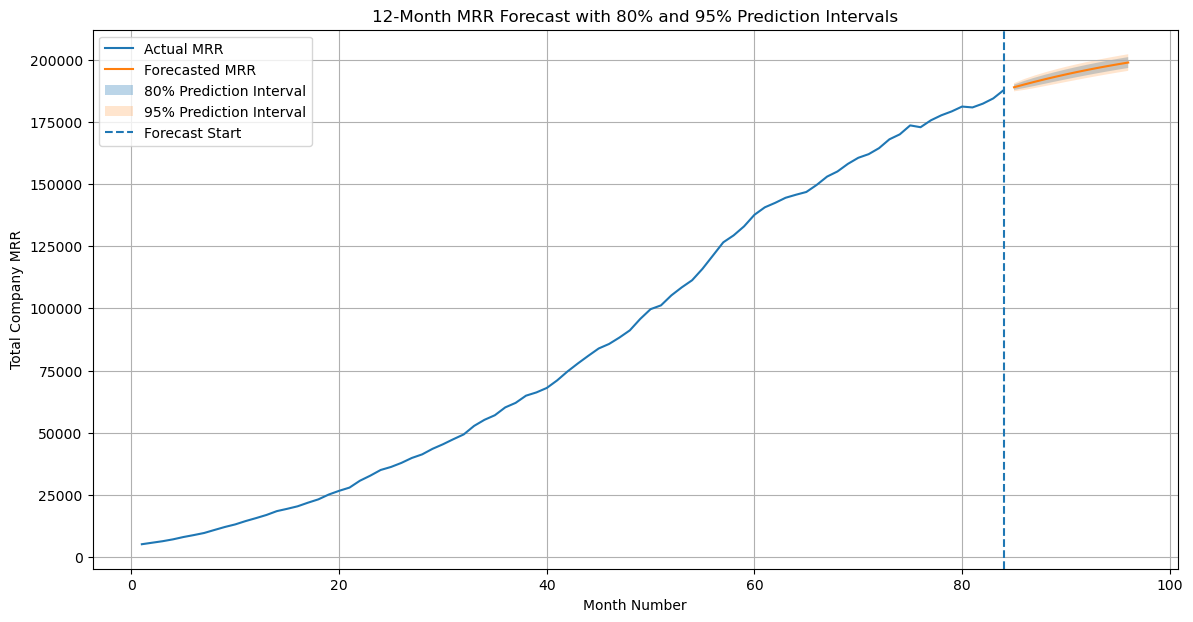

In [97]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

# Actual MRR
plt.plot(
    monthly_df["Month_Number"],
    monthly_df["Total_Company_MRR"],
    label="Actual MRR"
)

# Forecast
plt.plot(
    forecast_df["Month_Number"],
    forecast_df["Forecasted_MRR"],
    label="Forecasted MRR"
)

# 80% interval
plt.fill_between(
    forecast_df["Month_Number"],
    forecast_df["80_Lower"],
    forecast_df["80_Upper"],
    alpha=0.3,
    label="80% Prediction Interval"
)

# 95% interval
plt.fill_between(
    forecast_df["Month_Number"],
    forecast_df["95_Lower"],
    forecast_df["95_Upper"],
    alpha=0.2,
    label="95% Prediction Interval"
)

# Mark forecast starting point
plt.axvline(
    x=84,
    linestyle="--",
    label="Forecast Start"
)

plt.xlabel("Month Number")
plt.ylabel("Total Company MRR")
plt.title("12-Month MRR Forecast with 80% and 95% Prediction Intervals")
plt.legend()
plt.grid(True)

plt.show()

## Observation
The forecasted MRR shows a continued upward trend from Month 85 to Month 96.

Forecasted MRR increases from approximately 188,853 in Month 85 to 198,791 in Month 96.

The 80% prediction interval remains narrower than the 95% prediction interval, indicating a higher level of uncertainty in the wider 95% range.

The 95% prediction interval is wider and provides a broader range of possible future MRR values.

Both prediction intervals gradually widen as the forecast horizon increases, indicating that uncertainty increases for longer-term forecasts.

Overall, the chart indicates continued MRR growth with increasing uncertainty over the 12-month forecast period.

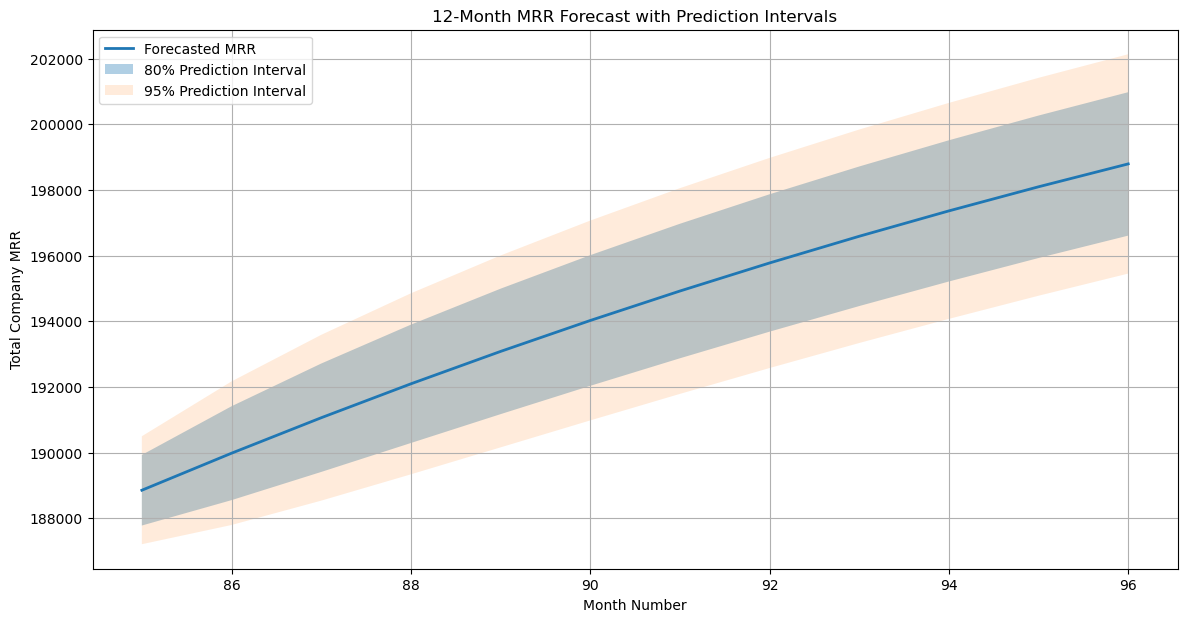

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

# Forecast line
plt.plot(
    forecast_df["Month_Number"],
    forecast_df["Forecasted_MRR"],
    label="Forecasted MRR",
    linewidth=2
)

# 80% Prediction Interval
plt.fill_between(
    forecast_df["Month_Number"],
    forecast_df["80_Lower"],
    forecast_df["80_Upper"],
    alpha=0.35,
    label="80% Prediction Interval"
)

# 95% Prediction Interval
plt.fill_between(
    forecast_df["Month_Number"],
    forecast_df["95_Lower"],
    forecast_df["95_Upper"],
    alpha=0.15,
    label="95% Prediction Interval"
)

plt.xlabel("Month Number")
plt.ylabel("Total Company MRR")
plt.title("12-Month MRR Forecast with Prediction Intervals")

plt.legend()
plt.grid(True)
plt.show()

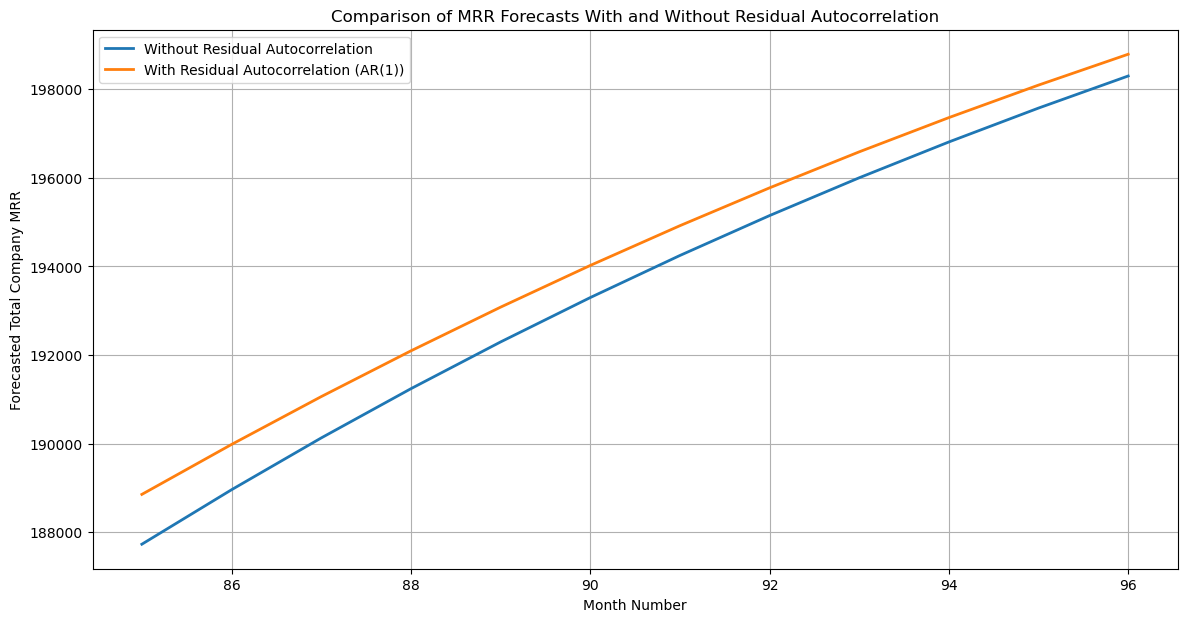

In [99]:
import matplotlib.pyplot as plt

# Forecast without handling residual autocorrelation
forecast_without_AR = future_logistic

# Forecast with handling residual autocorrelation
forecast_with_AR = future_forecast

plt.figure(figsize=(14, 7))

# Without residual autocorrelation
plt.plot(
    future_months,
    forecast_without_AR,
    label="Without Residual Autocorrelation",
    linewidth=2
)

# With residual autocorrelation
plt.plot(
    future_months,
    forecast_with_AR,
    label="With Residual Autocorrelation (AR(1))",
    linewidth=2
)

plt.xlabel("Month Number")
plt.ylabel("Forecasted Total Company MRR")
plt.title("Comparison of MRR Forecasts With and Without Residual Autocorrelation")

plt.legend()
plt.grid(True)
plt.show()